# Bitácora diagnóstica: clasificación de flores Iris

**Alumna:** Ana Cristina Munguía Romero  
**Matrícula:** A01740019
**Curso:** TC5061  
**Fuente:** [Iris Species — Kaggle](https://www.kaggle.com/datasets/uciml/iris)  
**Fecha de elaboración:** octubre de 2026  
**Uso de AI:** Se usó GPT-5.6 para guiar y revisar la actividad.

## Propósito
Desarrollar un punto de partida reproducible para clasificar una flor en una de tres especies —*setosa*, *versicolor* o *virginica*— utilizando únicamente medidas de sépalos y pétalos. La meta no es buscar el algoritmo más sofisticado, sino demostrar un flujo ordenado: conocer los datos, revisar su calidad, preparar las variables, entrenar un baseline, evaluar sus errores y registrar la evidencia en MLflow.

## Ruta de trabajo

Esta bitácora se organiza alrededor de cinco preguntas:

1. **¿Qué contiene el dataset?** Tamaño, tipos y significado de las variables.
2. **¿Qué patrones separan las especies?** Distribuciones y relaciones visuales.
3. **¿Qué debe corregirse?** Faltantes, duplicados, identificadores y valores extremos.
4. **¿Qué tan útil es un modelo sencillo?** Comparación de regresión logística contra un clasificador ingenuo.
5. **¿Cómo se conserva la evidencia?** Registro de parámetros, métricas, modelo y gráficas en MLflow.

La variable `Species` es categórica con tres clases, por lo que se trata de un problema de **clasificación multiclase**.

In [1]:
# Herramientas y constantes de reproducibilidad
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import platform
import sys
import warnings

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Image, Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 17
TEST_FRACTION = 0.25
ROOT = Path.cwd()
DATA_FILE = ROOT / "data" / "iris" / "Iris.csv"
IRIS_ARTIFACTS = ROOT / "artifacts" / "iris"
IRIS_ARTIFACTS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", context="notebook", palette="Set2")
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__} | MLflow {mlflow.__version__}")
print(platform.platform())

2026/10/04 17:44:18 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/anacristina/Documents/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Python 3.13.5 | pandas 3.0.6 | sklearn 1.9.1 | MLflow 3.16.1
macOS-27.0-arm64-arm-64bit-Mach-O


## Estación 1 — Obtener y reconocer los datos

El archivo utilizado es `Iris.csv` del dataset `uciml/iris` alojado en Kaggle. Si el CSV no se encuentra junto al proyecto, la siguiente celda descarga el ZIP mediante la API pública de Kaggle y extrae únicamente ese archivo.

In [2]:
if not DATA_FILE.exists():
    kaggle_download = "https://www.kaggle.com/api/v1/datasets/download/uciml/iris"
    DATA_FILE.parent.mkdir(parents=True, exist_ok=True)
    with urlopen(kaggle_download) as response, ZipFile(BytesIO(response.read())) as archive:
        DATA_FILE.write_bytes(archive.read("Iris.csv"))

iris_raw = pd.read_csv(DATA_FILE)
print(f"Dimensión original: {iris_raw.shape[0]} filas × {iris_raw.shape[1]} columnas")
display(iris_raw.sample(6, random_state=SEED).sort_values("Id"))
iris_raw.info()

Dimensión original: 150 filas × 6 columnas


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
16,17,5.4,3.9,1.3,0.4,Iris-setosa
78,79,6.0,2.9,4.5,1.5,Iris-versicolor
99,100,5.7,2.8,4.1,1.3,Iris-versicolor
126,127,6.2,2.8,4.8,1.8,Iris-virginica
127,128,6.1,3.0,4.9,1.8,Iris-virginica
145,146,6.7,3.0,5.2,2.3,Iris-virginica


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


### Diccionario breve

Cada registro corresponde a una flor:

- `Id`: consecutivo del registro; identifica la fila, no una propiedad botánica.
- `SepalLengthCm`: longitud del sépalo en centímetros.
- `SepalWidthCm`: ancho del sépalo en centímetros.
- `PetalLengthCm`: longitud del pétalo en centímetros.
- `PetalWidthCm`: ancho del pétalo en centímetros.
- `Species`: especie observada y variable objetivo.

Las cuatro medidas son continuas. La etiqueta pertenece a una de tres categorías balanceadas.

In [3]:
# Perfil descriptivo inicial
profile = iris_raw.describe(include="all").T
profile["faltantes"] = iris_raw.isna().sum()
profile["valores_unicos"] = iris_raw.nunique()
display(profile)

class_counts = iris_raw["Species"].value_counts().sort_index()
class_share = iris_raw["Species"].value_counts(normalize=True).sort_index().mul(100)
display(pd.concat([class_counts.rename("n"), class_share.rename("porcentaje")], axis=1))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max,faltantes,valores_unicos
Id,150.0,NaN,NaN,NaN,75.5,43.445368,1.0,38.25,75.5,112.75,150.0,0,150
SepalLengthCm,150.0,NaN,NaN,NaN,5.843333,0.828066,4.3,5.1,5.8,6.4,7.9,0,35
SepalWidthCm,150.0,NaN,NaN,NaN,3.054,0.433594,2.0,2.8,3.0,3.3,4.4,0,23
PetalLengthCm,150.0,NaN,NaN,NaN,3.758667,1.76442,1.0,1.6,4.35,5.1,6.9,0,43
PetalWidthCm,150.0,NaN,NaN,NaN,1.198667,0.763161,0.1,0.3,1.3,1.8,2.5,0,22
Species,150,3,Iris-setosa,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3


,n,porcentaje
Species,,
Iris-setosa,50,33.333333
Iris-versicolor,50,33.333333
Iris-virginica,50,33.333333


## Estación 2 — Mirar antes de modelar

El análisis exploratorio compara escalas, dispersión y separación entre especies. Se usan gráficas distintas para observar tanto cada variable individual como las combinaciones de medidas.

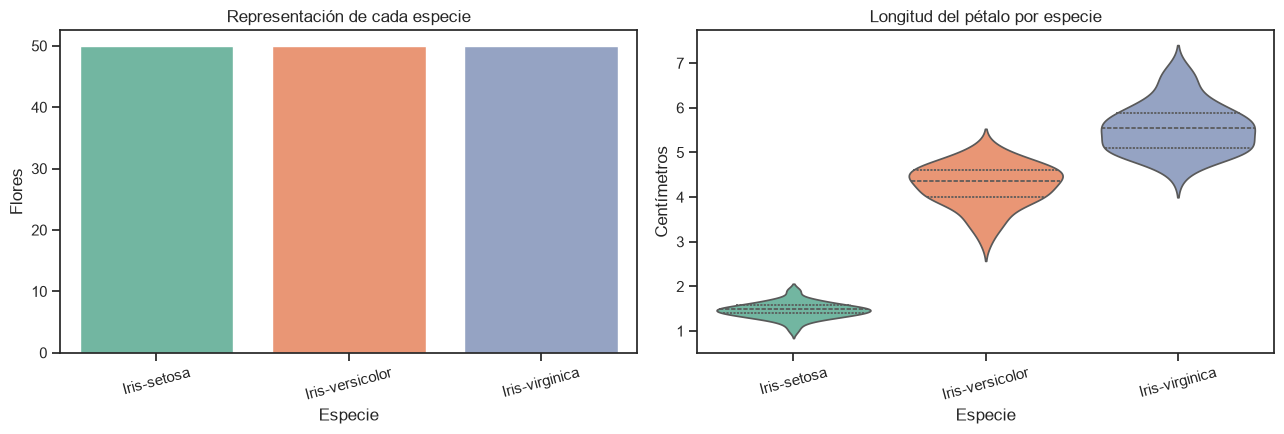

In [4]:
# Balance del objetivo y contraste de medidas por especie
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=iris_raw, x="Species", hue="Species", legend=False, ax=axes[0])
axes[0].set(title="Representación de cada especie", xlabel="Especie", ylabel="Flores")
axes[0].tick_params(axis="x", rotation=15)

sns.violinplot(data=iris_raw, x="Species", y="PetalLengthCm", hue="Species", legend=False, inner="quart", ax=axes[1])
axes[1].set(title="Longitud del pétalo por especie", xlabel="Especie", ylabel="Centímetros")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

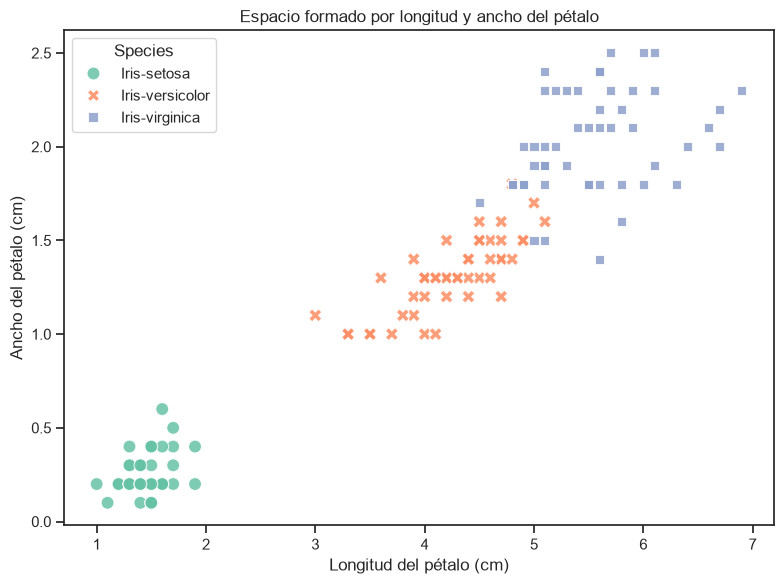

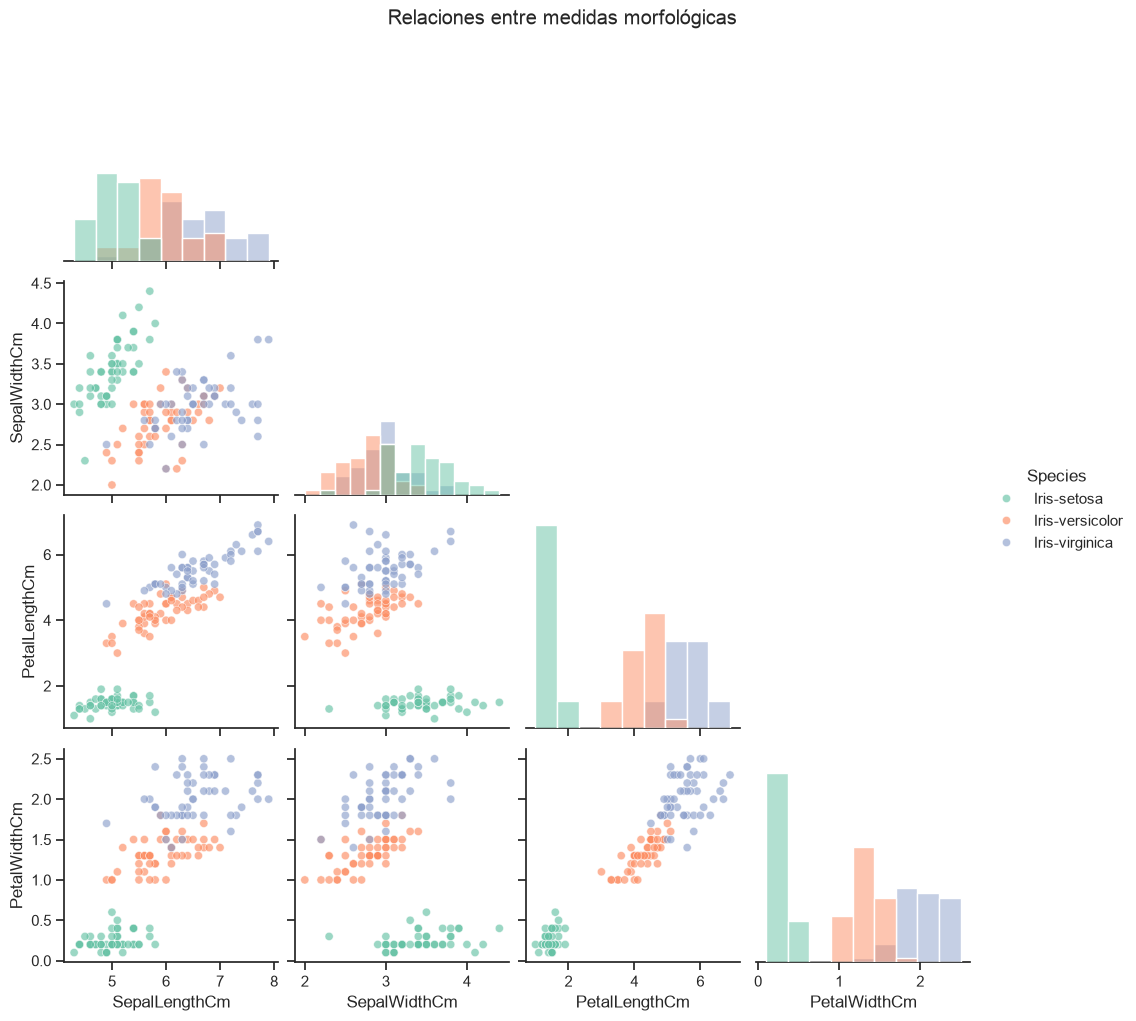

In [5]:
measure_columns = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

# Mapa bidimensional: dos rasgos particularmente informativos
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=iris_raw,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    style="Species",
    s=85,
    alpha=.85,
)
plt.title("Espacio formado por longitud y ancho del pétalo")
plt.xlabel("Longitud del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
plt.tight_layout()
petal_map_path = IRIS_ARTIFACTS / "petal_species_map.png"
plt.savefig(petal_map_path, dpi=160, bbox_inches="tight")
plt.show()

# Matriz compacta de relaciones
pair = sns.pairplot(
    iris_raw,
    vars=measure_columns,
    hue="Species",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": .65, "s": 35},
)
pair.fig.suptitle("Relaciones entre medidas morfológicas", y=1.02)
plt.show()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Species,,,,
Iris-setosa,5.010000,3.420000,1.460000,0.240000
Iris-versicolor,5.940000,2.770000,4.260000,1.330000
Iris-virginica,6.590000,2.970000,5.550000,2.030000


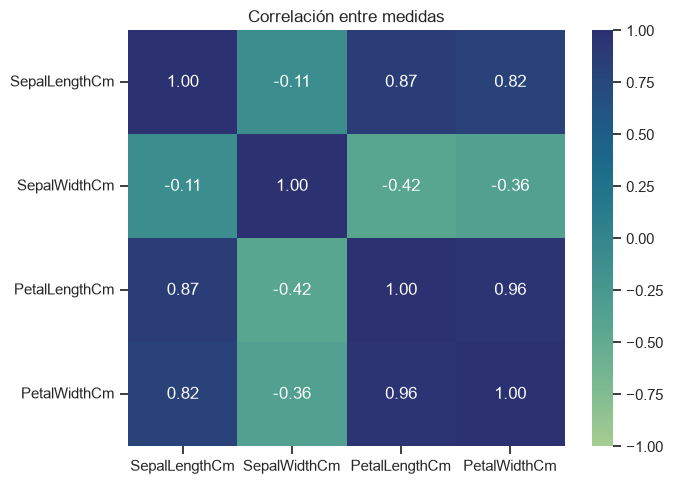

In [6]:
# Promedios por especie y correlaciones entre medidas
means_by_species = iris_raw.groupby("Species")[measure_columns].mean().round(2)
display(means_by_species.style.background_gradient(cmap="YlGnBu", axis=0))

plt.figure(figsize=(7, 5))
sns.heatmap(iris_raw[measure_columns].corr(), annot=True, fmt=".2f", cmap="crest", vmin=-1, vmax=1)
plt.title("Correlación entre medidas")
plt.tight_layout()
correlation_path = IRIS_ARTIFACTS / "iris_correlations.png"
plt.savefig(correlation_path, dpi=160, bbox_inches="tight")
plt.show()

### Lectura del EDA

- Las tres clases tienen exactamente 50 observaciones, así que no existe desbalance inicial.
- *Iris-setosa* queda claramente separada por sus pétalos cortos y estrechos.
- *Versicolor* y *virginica* se superponen parcialmente; ahí se concentrará la dificultad real del modelo.
- Longitud y ancho del pétalo presentan una asociación positiva fuerte. Las medidas del sépalo separan menos las clases, pero pueden aportar información complementaria.
- Las escalas son parecidas, aunque se estandarizarán dentro del pipeline para que los coeficientes de la regresión logística sean comparables.

## Estación 3 — Auditoría y limpieza

Las decisiones se toman antes de observar el conjunto de prueba:

- `Id` se elimina porque es un consecutivo sin significado botánico; conservarlo podría inducir patrones artificiales.
- Los nombres se cambian a `snake_case` y se retira el prefijo `Iris-` de las etiquetas para facilitar su lectura.
- Se comprueban faltantes, tipos y duplicados.
- Al retirar `Id` aparecen combinaciones idénticas de medidas y especie. **No se eliminan**, porque los identificadores originales confirman que corresponden a flores distintas con mediciones coincidentes.
- Los valores extremos se detectan por IQR, pero se conservan si están dentro de rangos botánicamente posibles. Un outlier estadístico no es automáticamente un error.

In [7]:
rename_map = {
    "SepalLengthCm": "sepal_length_cm",
    "SepalWidthCm": "sepal_width_cm",
    "PetalLengthCm": "petal_length_cm",
    "PetalWidthCm": "petal_width_cm",
    "Species": "species",
}
iris = iris_raw.drop(columns="Id").rename(columns=rename_map).copy()
iris["species"] = iris["species"].str.replace("Iris-", "", regex=False)

numeric_features = [c for c in iris.columns if c != "species"]
q1 = iris[numeric_features].quantile(.25)
q3 = iris[numeric_features].quantile(.75)
iqr = q3 - q1
outliers = (
    iris[numeric_features].lt(q1 - 1.5 * iqr)
    | iris[numeric_features].gt(q3 + 1.5 * iqr)
).sum()

audit = pd.DataFrame({
    "tipo": iris.dtypes.astype(str),
    "faltantes": iris.isna().sum(),
    "unicos": iris.nunique(),
    "outliers_IQR": outliers.reindex(iris.columns, fill_value=0),
})
display(audit)

print(f"Duplicados con Id: {iris_raw.duplicated().sum()}")
print(f"Mediciones coincidentes sin Id: {iris.duplicated().sum()} (se conservan por decisión documentada)")
assert iris.isna().sum().sum() == 0
assert iris["species"].nunique() == 3
display(iris.head())

,tipo,faltantes,unicos,outliers_IQR
sepal_length_cm,float64,0,35,0
sepal_width_cm,float64,0,23,4
petal_length_cm,float64,0,43,0
petal_width_cm,float64,0,22,0
species,str,0,3,0


Duplicados con Id: 0
Mediciones coincidentes sin Id: 3 (se conservan por decisión documentada)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Estación 4 — Baseline y protocolo de evaluación

Se reserva 25% de los datos para prueba con muestreo estratificado. De esta manera cada especie mantiene la misma representación en entrenamiento y prueba.

El pipeline contiene:

1. Imputación por mediana, aunque actualmente no existan faltantes; esto hace el flujo tolerante a futuras observaciones incompletas.
2. Estandarización aprendida únicamente con entrenamiento.
3. Regresión logística multiclase.

Como referencia mínima se utiliza `DummyClassifier(strategy="prior")`, que predice según la clase más frecuente. Se reportan `accuracy`, `balanced accuracy` y `F1 macro`; esta última exige buen desempeño en las tres especies.

In [8]:
X = iris.drop(columns="species")
y = iris["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_FRACTION,
    random_state=SEED,
    stratify=y,
)

iris_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])
naive_reference = DummyClassifier(strategy="prior", random_state=SEED)

naive_reference.fit(X_train, y_train)
iris_baseline.fit(X_train, y_train)

pred_naive = naive_reference.predict(X_test)
pred_iris = iris_baseline.predict(X_test)

print(f"Entrenamiento: {len(X_train)} flores | Prueba: {len(X_test)} flores")
display(pd.crosstab(y_test, columns="prueba").rename_axis(None, axis=1))

Entrenamiento: 112 flores | Prueba: 38 flores


,prueba
species,
setosa,12
versicolor,13
virginica,13


In [9]:
def classification_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }

naive_scores = classification_metrics(y_test, pred_naive)
model_scores = classification_metrics(y_test, pred_iris)
comparison = pd.DataFrame(
    [naive_scores, model_scores],
    index=["Referencia ingenua", "Regresión logística"],
)
display(comparison.round(4))

print("Reporte por especie:")
report = classification_report(y_test, pred_iris, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(3))

,accuracy,balanced_accuracy,f1_macro
Referencia ingenua,0.3158,0.3333,0.160
Regresión logística,0.9211,0.9231,0.923


Reporte por especie:


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12.000
versicolor,0.857,0.923,0.889,13.000
virginica,0.917,0.846,0.880,13.000
accuracy,0.921,0.921,0.921,0.921
macro avg,0.925,0.923,0.923,38.000
weighted avg,0.923,0.921,0.921,38.000


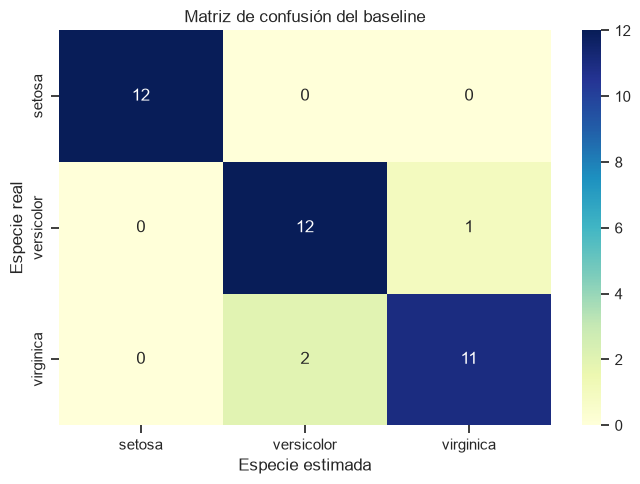

Errores encontrados en prueba: 3


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,real,estimada
77,6.7,3.0,5.0,1.7,versicolor,virginica
134,6.1,2.6,5.6,1.4,virginica,versicolor
106,4.9,2.5,4.5,1.7,virginica,versicolor


### Interpretación

El baseline alcanzó **accuracy de 0.921** y **F1 macro de 0.923**, frente a una accuracy de 0.316 del clasificador ingenuo. La diferencia confirma que las medidas morfológicas contienen información suficiente para separar las especies. El F1 macro es especialmente útil porque asigna el mismo peso a cada clase. La matriz de confusión permite identificar si los errores se concentran entre *versicolor* y *virginica*, tal como anticipó el EDA. Debido a que el conjunto solo contiene 150 flores, una sola partición puede producir una estimación optimista o inestable; por ello, estas cifras deben interpretarse como evidencia del baseline y no como garantía de desempeño futuro.

In [10]:
labels = iris_baseline.named_steps["classifier"].classes_
cm = confusion_matrix(y_test, pred_iris, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", xticklabels=labels, yticklabels=labels)
plt.title("Matriz de confusión del baseline")
plt.xlabel("Especie estimada")
plt.ylabel("Especie real")
plt.tight_layout()
confusion_path = IRIS_ARTIFACTS / "confusion_matrix.png"
plt.savefig(confusion_path, dpi=170, bbox_inches="tight")
plt.show()

mistakes = X_test.copy()
mistakes["real"] = y_test
mistakes["estimada"] = pred_iris
mistakes = mistakes[mistakes["real"] != mistakes["estimada"]]
print(f"Errores encontrados en prueba: {len(mistakes)}")
display(mistakes if len(mistakes) else Markdown("No hubo errores en esta partición de prueba."))

display(Markdown(
    f"""### Interpretación

El baseline alcanzó **accuracy de {model_scores['accuracy']:.3f}** y **F1 macro de {model_scores['f1_macro']:.3f}**, frente a una accuracy de {naive_scores['accuracy']:.3f} del clasificador ingenuo. La diferencia confirma que las medidas morfológicas contienen información suficiente para separar las especies. El F1 macro es especialmente útil porque asigna el mismo peso a cada clase. La matriz de confusión permite identificar si los errores se concentran entre *versicolor* y *virginica*, tal como anticipó el EDA. Debido a que el conjunto solo contiene 150 flores, una sola partición puede producir una estimación optimista o inestable; por ello, estas cifras deben interpretarse como evidencia del baseline y no como garantía de desempeño futuro."""
))

## Estación 5 — Trazabilidad con MLflow

Se crea un experimento separado para Iris. El registro incluye configuración, métricas del baseline y de la referencia ingenua, etiquetas, modelo y gráficas.

Para consultar la interfaz local después de ejecutar:

```bash
.venv/bin/mlflow ui --backend-store-uri sqlite:///mlflow_iris.db --port 5001
```

Luego se abre `http://127.0.0.1:5001` y se selecciona `TC5061_Iris_Clasificacion`.

In [11]:
iris_db = (ROOT / "mlflow_iris.db").resolve()
mlflow.set_tracking_uri(f"sqlite:///{iris_db}")
mlflow.set_experiment("TC5061_Iris_Clasificacion")

clean_preview = IRIS_ARTIFACTS / "iris_clean_preview.csv"
iris.head(30).to_csv(clean_preview, index=False)

with mlflow.start_run(
    run_name="logistic_regression_iris",
) as run:
    mlflow.log_params({
        "source": "Kaggle uciml/iris",
        "algorithm": "LogisticRegression",
        "test_fraction": TEST_FRACTION,
        "random_seed": SEED,
        "split": "stratified",
        "imputation": "median",
        "scaling": "StandardScaler",
        "rows": len(iris),
        "features": X.shape[1],
        "classes": y.nunique(),
        "identifier_removed": "Id",
    })
    mlflow.log_metrics({
        "test_accuracy": model_scores["accuracy"],
        "test_balanced_accuracy": model_scores["balanced_accuracy"],
        "test_f1_macro": model_scores["f1_macro"],
        "dummy_accuracy": naive_scores["accuracy"],
        "dummy_f1_macro": naive_scores["f1_macro"],
    })
    mlflow.set_tags({
        "student": "Ana Munguia",
        "course": "TC5061",
        "problem": "multiclass classification",
        "dataset_host": "Kaggle",
    })
    mlflow.log_artifact(str(clean_preview), artifact_path="data")
    mlflow.log_artifact(str(petal_map_path), artifact_path="figures")
    mlflow.log_artifact(str(correlation_path), artifact_path="figures")
    mlflow.log_artifact(str(confusion_path), artifact_path="figures")
    mlflow.sklearn.log_model(
        iris_baseline,
        name="iris_logistic_pipeline",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
    )
    iris_run_id = run.info.run_id

print(f"Run completado: {iris_run_id}")
print(f"Tracking URI: {mlflow.get_tracking_uri()}")

2026/10/04 17:44:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Run completado: 663a2483315c4325aa7c73e9f196450a
Tracking URI: sqlite:////Users/anacristina/Documents/mlflow_iris.db


## Evidencia visual del experimento

La captura debe mostrar el nombre del run, su estado, las métricas y los parámetros registrados. Se almacena en `artifacts/iris/mlflow_iris_experiment.png` y queda incrustada en la salida del notebook.

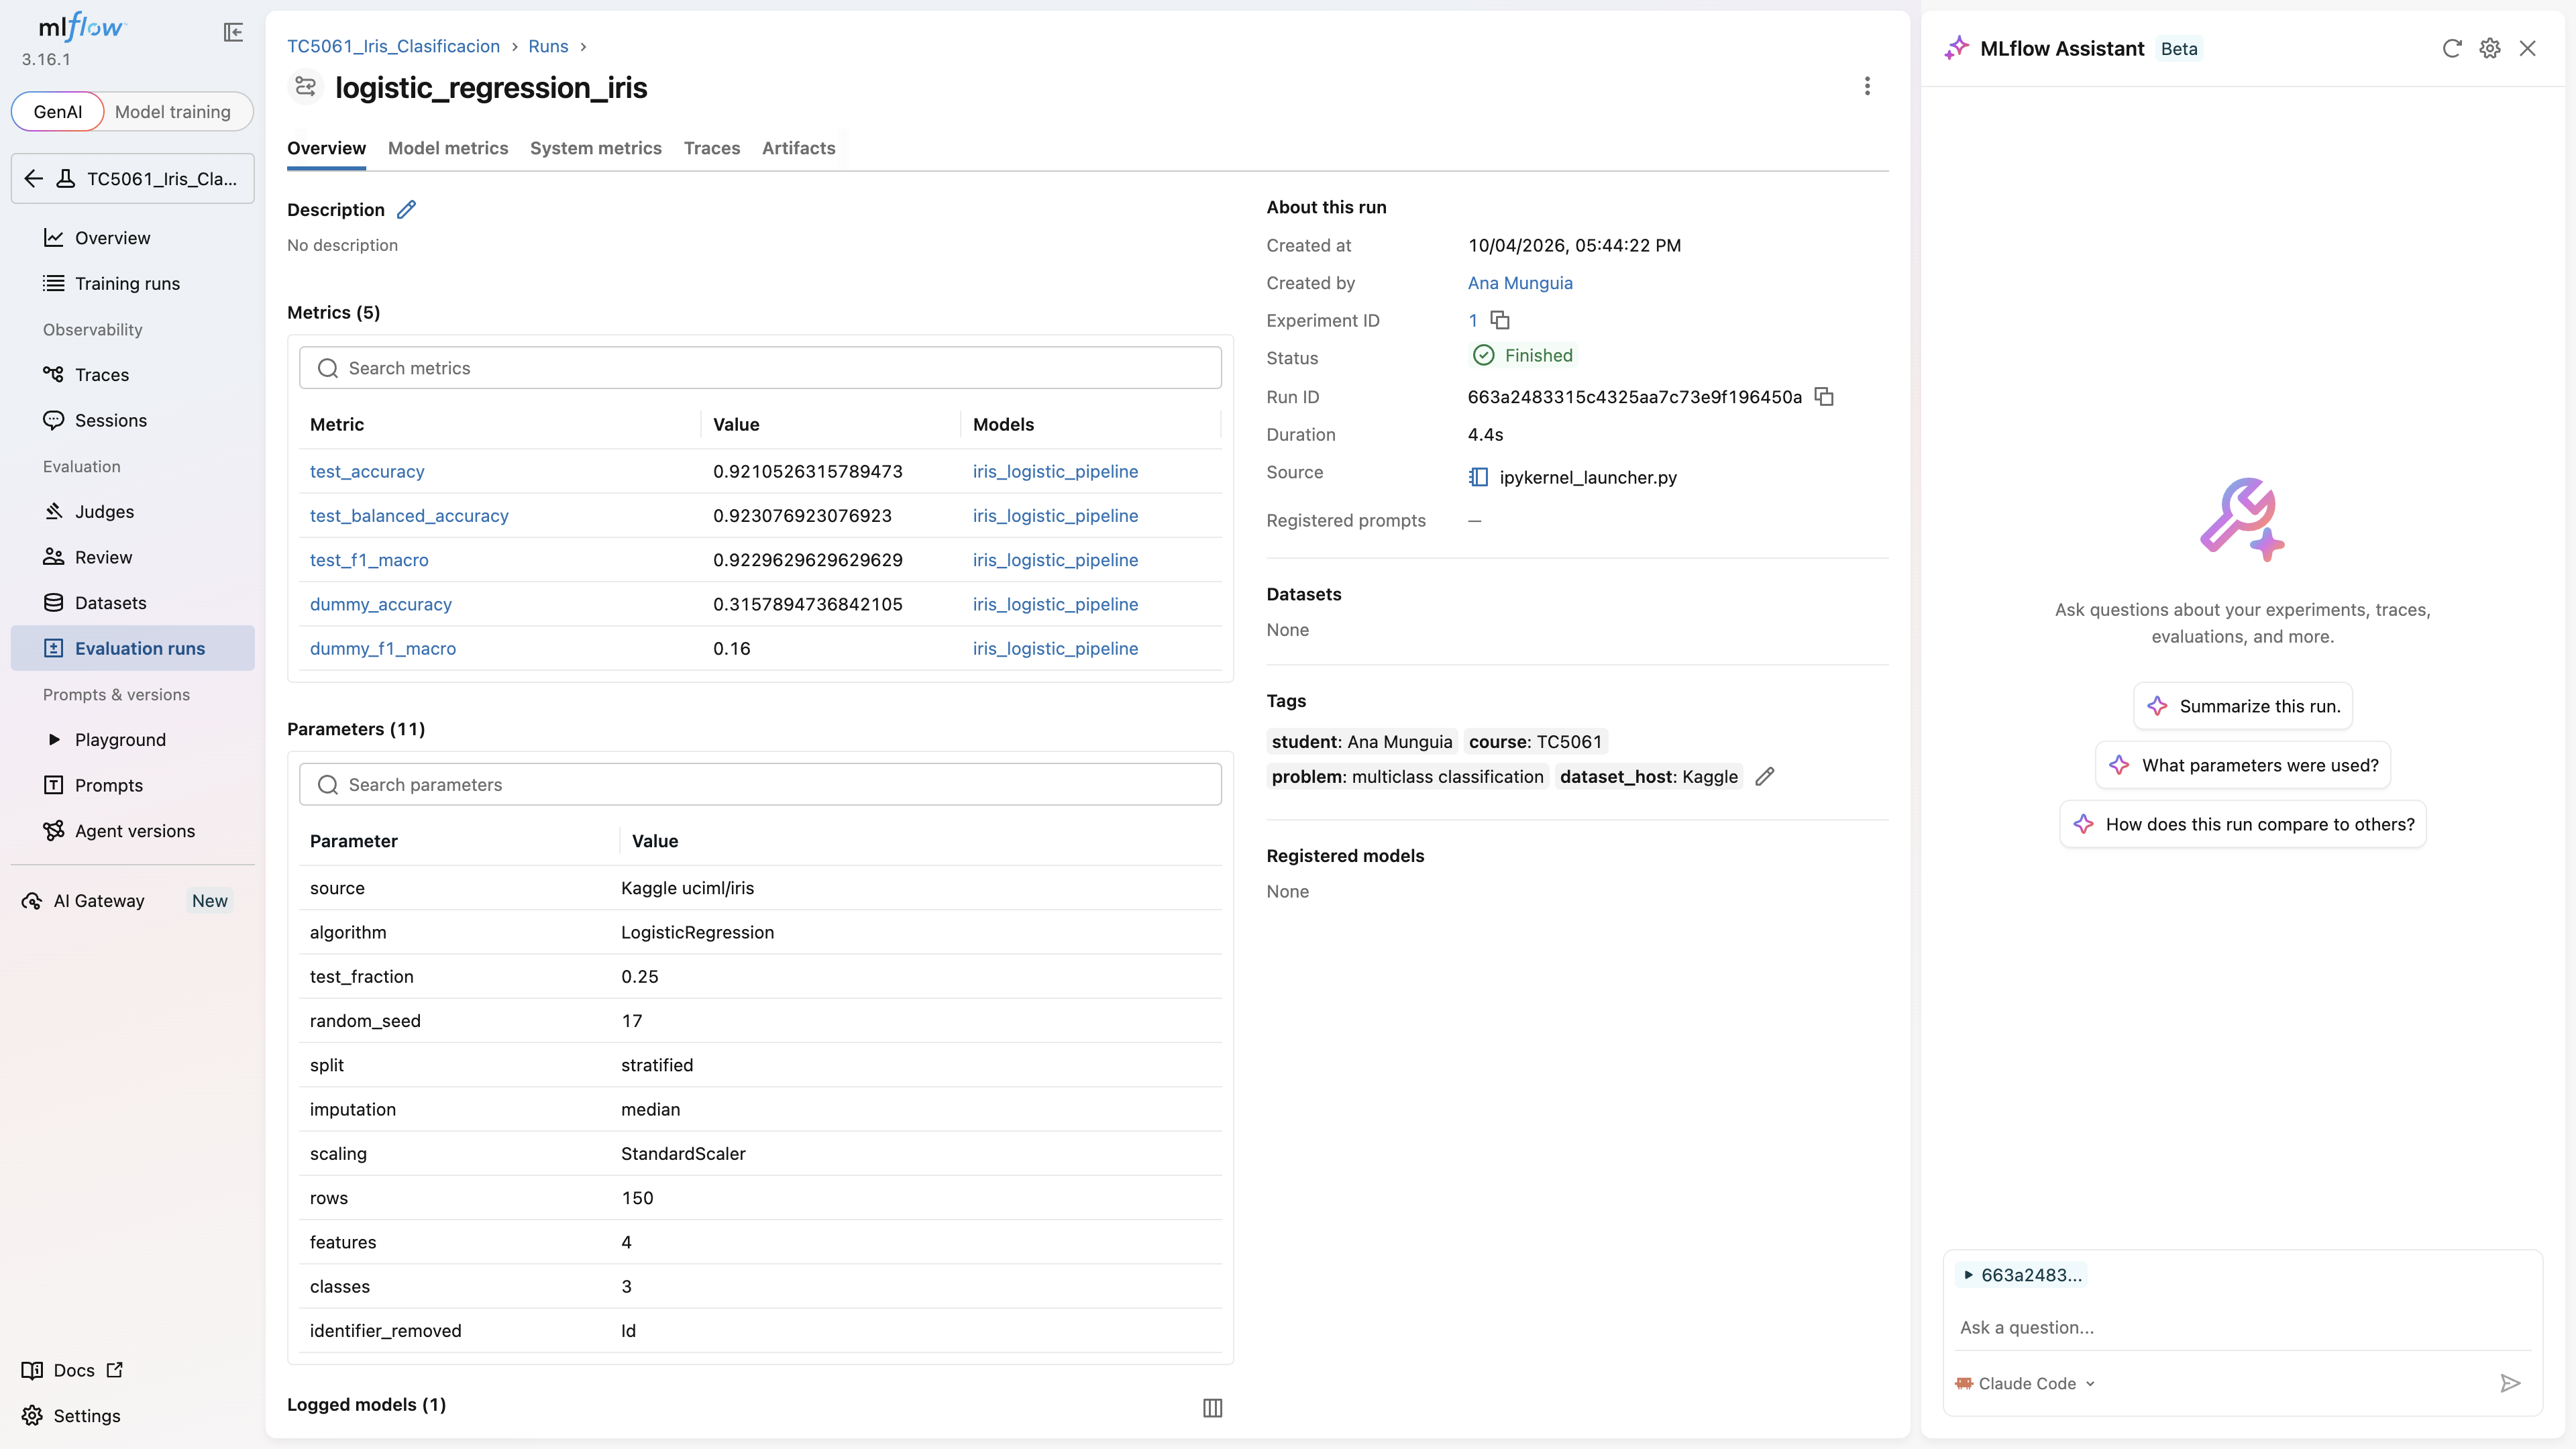

In [12]:
iris_mlflow_image = IRIS_ARTIFACTS / "mlflow_iris_experiment.png"
if iris_mlflow_image.exists():
    display(Image(filename=str(iris_mlflow_image)))
else:
    display(Markdown(
        "⚠️ Falta la captura. Abre la interfaz de MLflow, entra al run y guarda la imagen "
        "como `artifacts/iris/mlflow_iris_experiment.png`."
    ))

## Reflexión personal

Recorrer este flujo me permitió entender que un proyecto de Machine Learning comienza mucho antes del entrenamiento. En Iris, el tamaño pequeño y el balance perfecto hacen que el problema parezca sencillo, pero aun así fue necesario cuestionar cada columna. El identificador `Id`, por ejemplo, no describe a la flor y podía introducir una relación artificial. También aprendí que dos filas con las mismas medidas no necesariamente son registros duplicados: al conservar identificadores distintos, pueden representar flores diferentes que coinciden después del redondeo. De forma similar, los valores señalados por IQR no se eliminaron automáticamente, porque primero debe existir evidencia de que son errores.

Para mejorar este trabajo aplicaría validación cruzada estratificada y compararía el baseline con árboles de decisión, K vecinos y máquinas de soporte vectorial. También incluiría pruebas automáticas para verificar esquema, unidades, rangos y clases esperadas; versionaría datos y código; y registraría en MLflow cada alternativa bajo el mismo protocolo. En producción sería necesario vigilar cambios en las medidas de nuevas flores, desempeño por especie y confianza de las predicciones. Si aparecieran especies no contempladas, el sistema debería abstenerse de responder en vez de forzar una categoría conocida.

Dentro de mi área profesional, estos aprendizajes se relacionan con diseñar soluciones confiables y comunicables. No basta con mostrar una métrica alta: hay que explicar qué representa, contra qué referencia se comparó y cuáles son sus límites. La trazabilidad de MLflow facilita que otras personas reproduzcan el análisis, revisen decisiones y continúen el trabajo sin depender de la memoria de quien creó el primer modelo.

## Cierre y referencias

El baseline cumple su función: establece un resultado reproducible, supera una referencia ingenua y hace visibles sus errores. La mejora futura debe centrarse en una evaluación más estable, no solamente en aumentar la complejidad del algoritmo.

### Referencias

- UCI Machine Learning. (2016). *Iris Species* [Dataset]. Kaggle. https://www.kaggle.com/datasets/uciml/iris
- Fisher, R. A. (1936). *The use of multiple measurements in taxonomic problems*. Annals of Eugenics, 7(2), 179–188.
- Scikit-learn Developers. *LogisticRegression documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html